Target column used : class | bad = 300 / 1000
Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.77 ROC-AUC : 0.83

GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK  FEATURE                     MEAN|SHAP|
---------------------------------------------
1     checking_status             0.092
2     duration                    0.042
3     credit_amount               0.027
4     savings_status              0.027
5     purpose                     0.025
---------------------------------------------


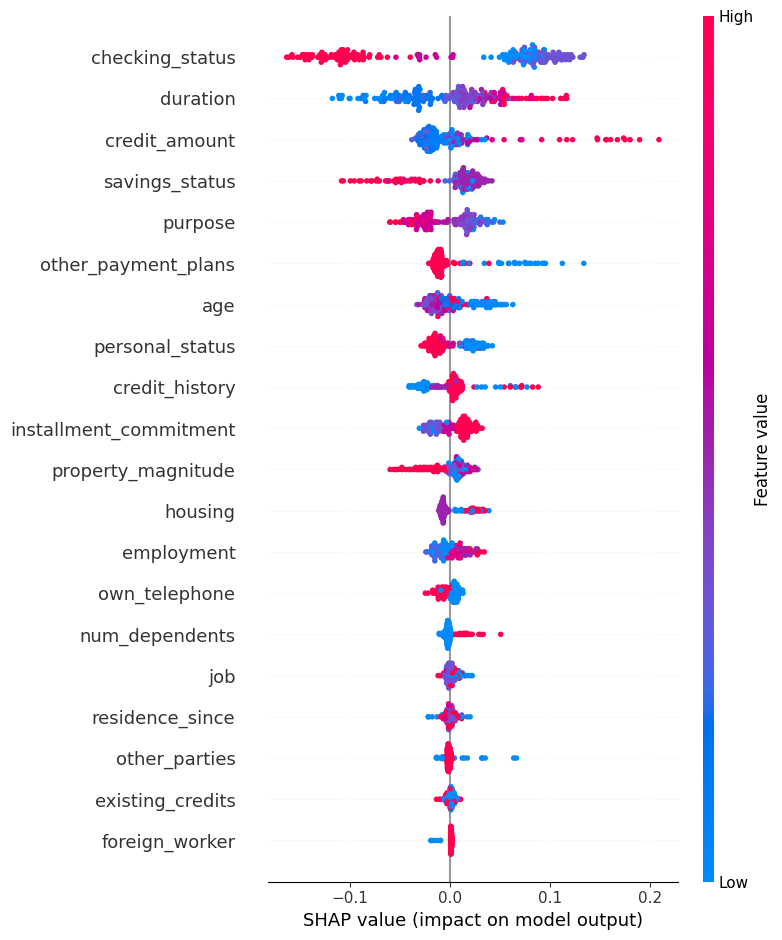

Plot saved : shap_summary.png

Applicant (test index 23) : P(bad) = 0.57 -> REJECTED


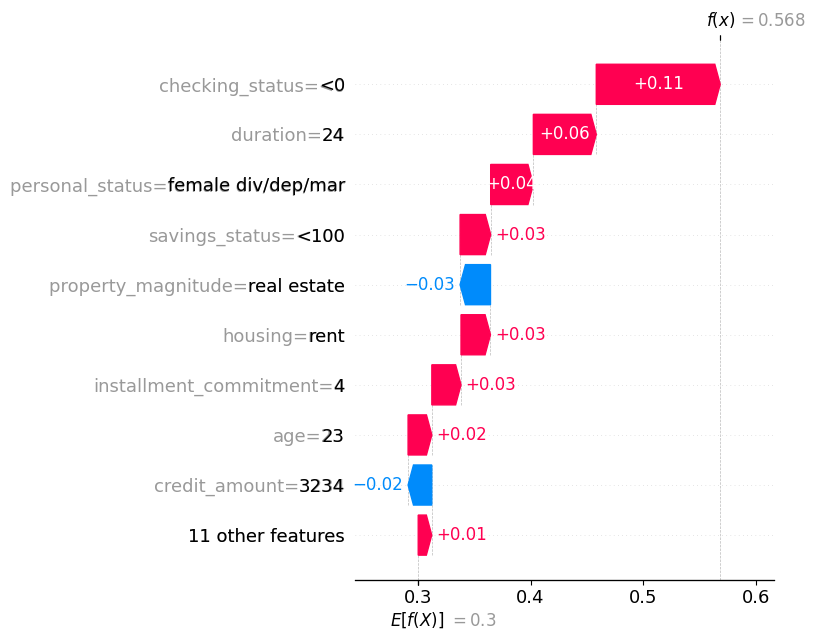

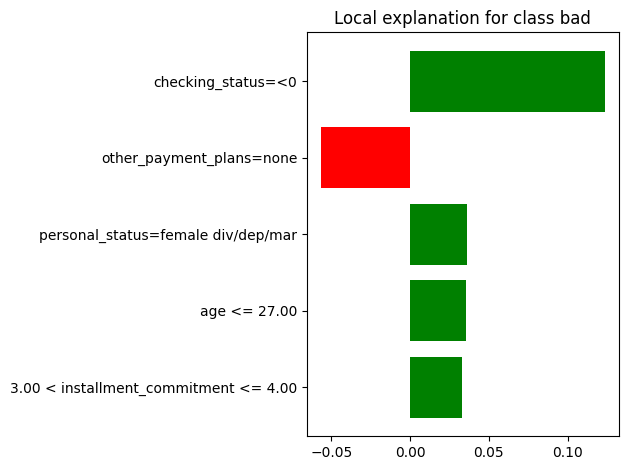


SHAP (top 3)                                      LIME (top 5)
----------------------------------------------------------------------------------------------------
checking_status=<0 +0.11                          checking_status=<0 +0.12
duration=24 +0.06                                 other_payment_plans=none -0.06
personal_status=female div/dep/mar +0.04          personal_status=female div/dep/mar +0.04
                                                  age <= 27.00 +0.04
                                                  3.00 < installment_commitment <= 4.00 +0.03
----------------------------------------------------------------------------------------------------
Top-3 agreement (SHAP vs LIME) : 2 / 3
Sensitive attributes in reasons : age, personal_status -> REVIEW
Message (legitimate reasons only): "Your EMI request was not approved mainly because your current account balance is negative and the requested duration (24 months) is long."


In [5]:
# ============ Install (Colab) ============
!pip install -q shap lime

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# ============ Task 1: Load, encode, split ============
cands = ["class", "risk", "credit_risk", "creditrisk", "target", "default", "label",
         "creditability", "credit_rating", "kredit", "good_loan"]

def find_target(d):
    low = {c.lower().strip().replace(" ", "_"): c for c in d.columns}
    return next((low[k] for k in cands if k in low), None)

df, target = None, None
if os.path.exists("german_credit_data.csv"):
    d = pd.read_csv("german_credit_data.csv", sep=None, engine="python")
    d.columns = [str(c).strip() for c in d.columns]
    d = d.loc[:, ~d.columns.str.lower().str.startswith("unnamed")]
    t = find_target(d)
    if t is not None:
        df, target = d, t

if df is None:   # no CSV, or CSV has no label column -> standard UCI German Credit (OpenML credit-g)
    from sklearn.datasets import fetch_openml
    df = fetch_openml("credit-g", version=1, as_frame=True, parser="auto").frame
    target = "class"

def to_bad(s, name):
    s2 = s.astype(str).str.strip().str.lower()
    vals = set(s2.unique())
    if {"bad", "good"} & vals:
        return (s2 == "bad").astype(int)
    if vals <= {"1", "2", "1.0", "2.0"}:               # UCI coding: 1 = good, 2 = bad
        return s2.isin(["2", "2.0"]).astype(int)
    if vals <= {"0", "1", "0.0", "1.0"}:
        if any(k in name.lower() for k in ["creditab", "good", "rating"]):
            return s2.isin(["0", "0.0"]).astype(int)
        return s2.isin(["1", "1.0"]).astype(int)
    if {"yes", "no"} & vals:
        return (s2 == "yes").astype(int)
    top = s2.value_counts().index[-1]
    return (s2 == top).astype(int)

y = to_bad(df[target], target)                          # bad = 1 (positive class)
X = df.drop(columns=[target]).copy()
X = X.fillna(X.mode().iloc[0])

cat_cols = [c for c in X.columns if X[c].dtype == "object" or str(X[c].dtype) in ("category", "string", "bool")]
X[cat_cols] = X[cat_cols].astype(str)
enc = OrdinalEncoder()
if cat_cols:
    X[cat_cols] = enc.fit_transform(X[cat_cols])
X = X.astype(float)
feature_names = list(X.columns)
cat_idx = [feature_names.index(c) for c in cat_cols]
cat_names = {feature_names.index(c): [str(v) for v in enc.categories_[i]] for i, c in enumerate(cat_cols)}

print(f"Target column used : {target} | bad = {int(y.sum())} / {len(y)}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# ============ Task 2: Random Forest ============
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf.fit(X_train, y_train)
proba = rf.predict_proba(X_test)[:, 1]
acc = accuracy_score(y_test, rf.predict(X_test))
auc = roc_auc_score(y_test, proba)
print("Model : RandomForest (200 trees, depth 8)")
print(f"Test accuracy : {acc:.2f} ROC-AUC : {auc:.2f}")

# ============ Task 3: SHAP global importance ============
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(X_test)
if isinstance(sv, list):
    sv = sv[1]
elif np.ndim(sv) == 3:
    sv = sv[:, :, 1]
sv = np.asarray(sv)
ev = explainer.expected_value
ev = float(np.ravel(ev)[-1]) if np.size(ev) > 1 else float(np.ravel(ev)[0])

mean_abs = np.abs(sv).mean(axis=0)
order = np.argsort(-mean_abs)
print("\nGLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print(f"{'RANK':<6}{'FEATURE':<28}{'MEAN|SHAP|'}")
print("-" * 45)
for r, i in enumerate(order[:5], 1):
    print(f"{r:<6}{feature_names[i]:<28}{mean_abs[i]:.3f}")
print("-" * 45)

plt.figure()
shap.summary_plot(sv, X_test, feature_names=feature_names, show=False)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved : shap_summary.png")

# ============ Helper: readable feature values ============
def readable(row):
    out = {}
    for j, f in enumerate(feature_names):
        v = row[j]
        if j in cat_names:
            out[f] = str(cat_names[j][int(v)])
        else:
            out[f] = str(int(v)) if float(v).is_integer() else f"{v:.2f}"
    return out

# ============ Task 4: SHAP local explanation (rejected applicant) ============
rejected_pos = np.where(proba >= 0.5)[0]
pos = int(rejected_pos[0]) if len(rejected_pos) else int(np.argmax(proba))
x_row = X_test.iloc[pos].values
p_bad = proba[pos]
disp = readable(x_row)
status = "REJECTED" if p_bad >= 0.5 else "HIGHEST-RISK (below 0.5 threshold)"
print(f"\nApplicant (test index {pos}) : P(bad) = {p_bad:.2f} -> {status}")

sv_i = sv[pos]
shap_order = np.argsort(-sv_i)
shap_top3 = [i for i in shap_order if sv_i[i] > 0][:3]

plt.figure()
shap.plots.waterfall(
    shap.Explanation(values=sv_i, base_values=ev,
                     feature_names=[f"{f}={disp[f]}" for f in feature_names]),
    max_display=10, show=False)
plt.tight_layout()
plt.savefig("shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

# ============ Task 5: LIME ============
lime_exp = LimeTabularExplainer(
    X_train.values, feature_names=feature_names, class_names=["good", "bad"],
    categorical_features=cat_idx, categorical_names=cat_names,
    mode="classification", discretize_continuous=True, random_state=42)
exp = lime_exp.explain_instance(
    x_row, lambda a: rf.predict_proba(pd.DataFrame(a, columns=feature_names)),
    num_features=5, labels=(1,))
lime_map = exp.as_map()[1]
lime_str = dict(zip([m[0] for m in lime_map], [t[0] for t in exp.as_list(label=1)]))

fig = exp.as_pyplot_figure(label=1)
plt.tight_layout()
plt.savefig("lime_explanation.png", dpi=150, bbox_inches="tight")
plt.show()

lime_pos = [(i, w) for i, w in sorted(lime_map, key=lambda t: -t[1]) if w > 0]
lime_top3 = [i for i, _ in lime_pos[:3]]

print(f"\n{'SHAP (top 3)':<50}{'LIME (top 5)'}")
print("-" * 100)
shap_lines = [f"{feature_names[i]}={disp[feature_names[i]]} {sv_i[i]:+.2f}" for i in shap_top3]
lime_lines = [f"{lime_str[i]} {w:+.2f}" for i, w in lime_map]
for k in range(max(len(shap_lines), len(lime_lines))):
    a = shap_lines[k] if k < len(shap_lines) else ""
    b = lime_lines[k] if k < len(lime_lines) else ""
    print(f"{a:<50}{b}")
print("-" * 100)

agree = len(set(shap_top3) & set(lime_top3))
print(f"Top-3 agreement (SHAP vs LIME) : {agree} / 3")

# ============ Task 6: Message + sensitive attribute check ============
def is_sensitive(name):
    n = name.lower()
    return n == "age" or "personal" in n or "foreign" in n or "sex" in n or "gender" in n

all_reason_idx = set(shap_top3) | {i for i, w in lime_map if w > 0}
found = sorted({feature_names[i] for i in all_reason_idx if is_sensitive(feature_names[i])})
print("Sensitive attributes in reasons :", ", ".join(found) if found else "None",
      "-> REVIEW" if found else "-> OK")

def phrase(f, v):
    plain = {
        "checking_status": {"<0": "your current account balance is negative",
                            "0<=X<200": "your current account balance is low",
                            ">=200": "your current account balance is only moderate",
                            "no checking": "you do not have a checking account"},
        "savings_status": {"<100": "your savings are very low",
                           "100<=X<500": "your savings are low",
                           "500<=X<1000": "your savings are only moderate",
                           ">=1000": "your savings level is adequate but other factors weighed against approval",
                           "no known savings": "no savings are on record"},
        "credit_history": {"critical/other existing credit": "your credit history shows other existing credit obligations",
                           "delayed previously": "your credit history shows previously delayed payments",
                           "existing paid": "your existing credits are being repaid",
                           "all paid": "your previous credits were fully repaid",
                           "no credits/all paid": "no previous credit history is available"},
        "employment": {"unemployed": "you are currently unemployed",
                       "<1": "your current employment is less than one year old",
                       "1<=X<4": "your employment history is short"},
        "other_payment_plans": {"bank": "you already have other payment plans with a bank",
                                "stores": "you already have other payment plans with stores"},
        "property_magnitude": {"no known property": "no property or assets are on record",
                               "car": "your recorded assets are limited",
                               "life insurance": "your recorded assets are limited"},
        "housing": {"rent": "you are living in rented housing",
                    "for free": "your housing status is not owned"},
    }
    if f in plain and v in plain[f]:
        return plain[f][v]
    t = {
        "duration": f"the requested duration ({v} months) is long",
        "credit_amount": f"the requested credit amount ({v}) is high",
        "purpose": f"the purpose of the loan ('{v}') carries higher risk",
        "installment_commitment": f"the installment burden relative to income is high (level {v})",
        "existing_credits": f"you already have {v} existing credit(s)",
        "residence_since": f"your time at the current residence ({v} years) is short",
        "num_dependents": f"the number of dependents ({v}) increases your financial commitments",
        "job": f"your job category ('{v}') was considered",
        "own_telephone": "no registered telephone was found",
        "other_parties": f"other parties on the loan ('{v}') were considered",
    }
    return t.get(f, f"your '{f}' value ('{v}') increased the risk")

legit = [i for i in shap_order if sv_i[i] > 0 and not is_sensitive(feature_names[i])][:2]
reasons = [phrase(feature_names[i], disp[feature_names[i]]) for i in legit]
msg = "Your EMI request was not approved mainly because " + " and ".join(reasons) + "."
print('Message (legitimate reasons only): "' + msg + '"')